In [279]:
import matplotlib.pyplot as plt
import os
import cv2 as cv 
import numpy as np

In [280]:
image_dir = os.path.join(os.getcwd(), "Database_134_Angiograms")
ground_truth_images = [f for f in os.listdir(image_dir) if f.endswith('_gt.pgm')]
original_images = [f for f in os.listdir(image_dir) if f.endswith('.pgm') and not f.endswith('_gt.pgm')]
# Sort filenames by their numeric image ID
original_images.sort(key=lambda name: int(os.path.splitext(name)[0]))
ground_truth_images.sort(key=lambda name: int(name.split('_')[0]))

print("Ground Truth Images:", ground_truth_images)
print("Original Images:", original_images)

Ground Truth Images: ['1_gt.pgm', '2_gt.pgm', '3_gt.pgm', '4_gt.pgm', '5_gt.pgm', '6_gt.pgm', '7_gt.pgm', '8_gt.pgm', '9_gt.pgm', '10_gt.pgm', '11_gt.pgm', '12_gt.pgm', '13_gt.pgm', '14_gt.pgm', '15_gt.pgm', '16_gt.pgm', '17_gt.pgm', '18_gt.pgm', '19_gt.pgm', '20_gt.pgm', '21_gt.pgm', '22_gt.pgm', '23_gt.pgm', '24_gt.pgm', '25_gt.pgm', '26_gt.pgm', '27_gt.pgm', '28_gt.pgm', '29_gt.pgm', '30_gt.pgm', '31_gt.pgm', '32_gt.pgm', '33_gt.pgm', '34_gt.pgm', '35_gt.pgm', '36_gt.pgm', '37_gt.pgm', '38_gt.pgm', '39_gt.pgm', '40_gt.pgm', '41_gt.pgm', '42_gt.pgm', '43_gt.pgm', '44_gt.pgm', '45_gt.pgm', '46_gt.pgm', '47_gt.pgm', '48_gt.pgm', '49_gt.pgm', '50_gt.pgm', '51_gt.pgm', '52_gt.pgm', '53_gt.pgm', '54_gt.pgm', '55_gt.pgm', '56_gt.pgm', '57_gt.pgm', '58_gt.pgm', '59_gt.pgm', '60_gt.pgm', '61_gt.pgm', '62_gt.pgm', '63_gt.pgm', '64_gt.pgm', '65_gt.pgm', '66_gt.pgm', '67_gt.pgm', '68_gt.pgm', '69_gt.pgm', '70_gt.pgm', '71_gt.pgm', '72_gt.pgm', '73_gt.pgm', '74_gt.pgm', '75_gt.pgm', '76_gt.pgm',

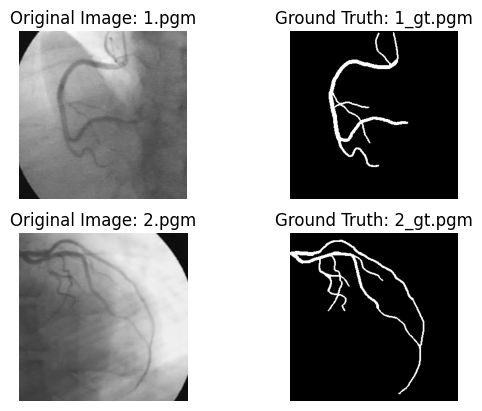

In [281]:
# Plot first two images with ground truth images
for i in range(2):
    plt.subplot(2, 2, 2*i + 1)
    img = cv.imread(os.path.join(image_dir, original_images[i]), cv.IMREAD_GRAYSCALE)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image: ' + original_images[i])
    plt.axis('off')

    plt.subplot(2, 2, 2*i + 2)
    gt = cv.imread(os.path.join(image_dir, ground_truth_images[i]), cv.IMREAD_GRAYSCALE)
    plt.imshow(gt, cmap='gray')
    plt.title('Ground Truth: ' + ground_truth_images[i])
    plt.axis('off')

plt.show()

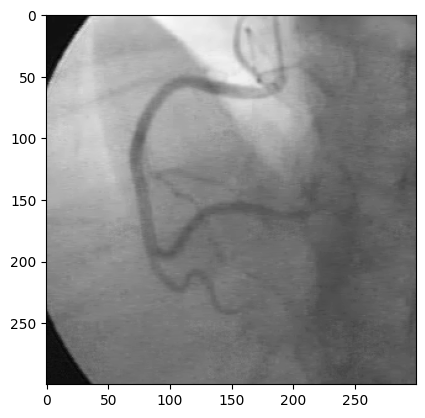

In [282]:
image1 = cv.imread(os.path.join(image_dir, original_images[0]), cv.IMREAD_GRAYSCALE)
plt.imshow(image1, cmap='gray')

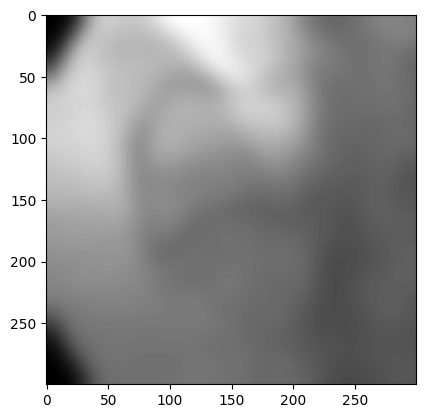

In [314]:
very_blurred_image = cv.GaussianBlur(image1, (59, 59), 0)
plt.imshow(very_blurred_image, cmap='gray')


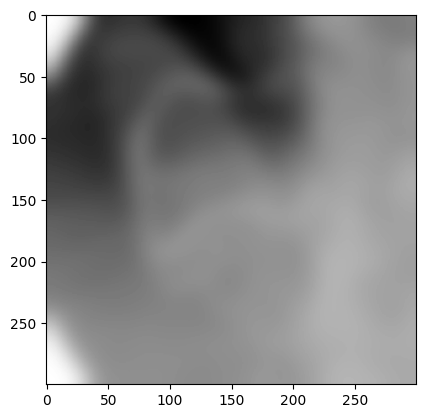

In [315]:
negative_of_blurred_image = 255 - very_blurred_image
plt.imshow(negative_of_blurred_image, cmap='gray')

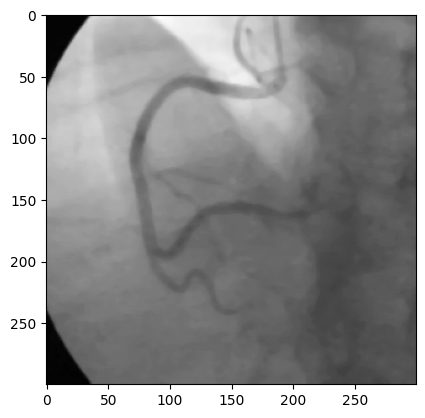

In [316]:
median_image = cv.medianBlur(image1, 5)
plt.imshow(median_image, cmap='gray')

In [326]:
def normalize_image(image):
    # Normalize the image to the range [0, 255]
    normalized_image = cv.normalize(image, None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX)
    return normalized_image.astype(np.uint8)

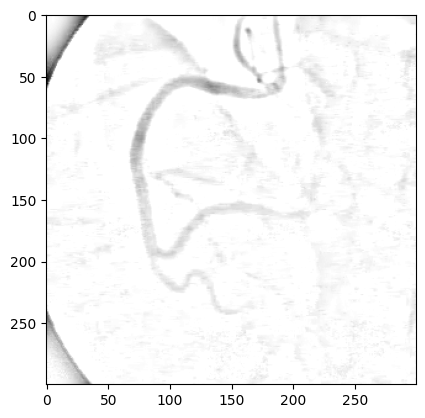

In [327]:
original_image_added_with_neg_very_blurred_image = cv.add(image1, negative_of_blurred_image)
original_image_added_with_neg_very_blurred_image = normalize_image(original_image_added_with_neg_very_blurred_image)
plt.imshow(original_image_added_with_neg_very_blurred_image, cmap='gray')

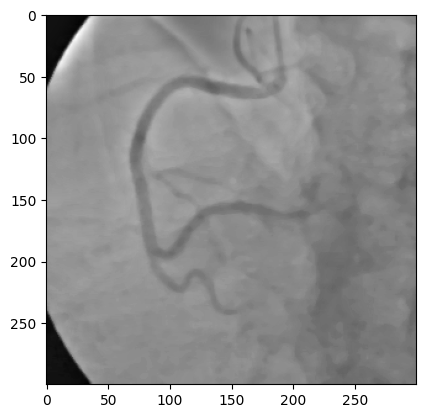

In [343]:
# dot product every pixel of the original image with the negative of the blurred image
multiplied_image = normalize_image(np.multiply(np.float32(median_image), np.float32(negative_of_blurred_image)))
plt.imshow(multiplied_image, cmap='gray')

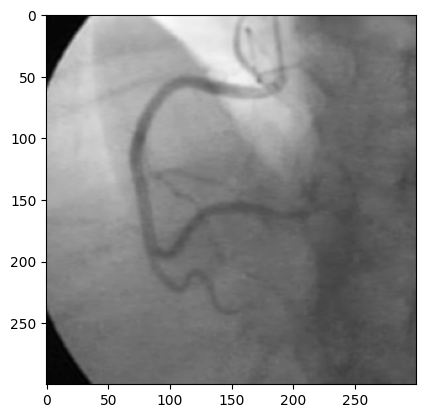

In [318]:
blur_image = cv.GaussianBlur(image1, (3, 3), 0)
plt.imshow(blur_image, cmap='gray')

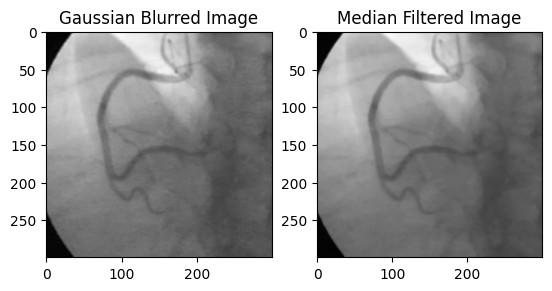

In [286]:
plt.subplot(1, 2, 1)
plt.imshow(blur_image, cmap='gray')
plt.title('Gaussian Blurred Image')

plt.subplot(1, 2, 2)
plt.imshow(median_image, cmap='gray')
plt.title('Median Filtered Image')
plt.show()

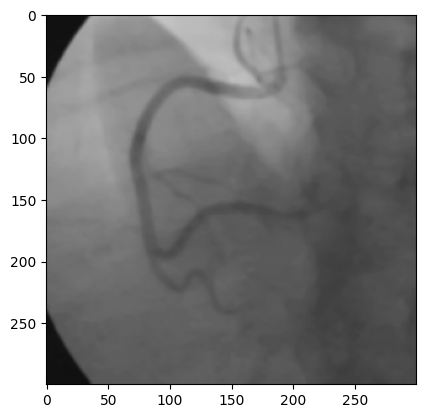

In [287]:
blureed_after_median = cv.GaussianBlur(median_image.astype(np.uint8), (3, 3), 0)
plt.imshow(blureed_after_median, cmap='gray', vmin=0, vmax=255)

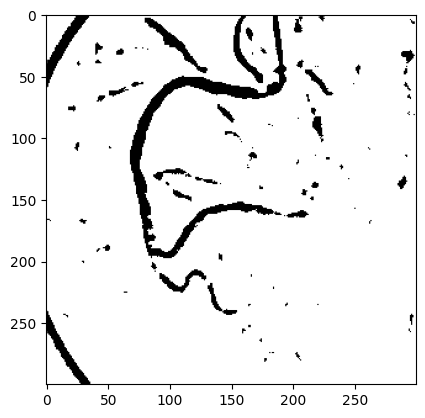

In [288]:
adaptive_tresholed_image = cv.adaptiveThreshold(blureed_after_median.astype(np.uint8), 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 25, 4)
plt.imshow(adaptive_tresholed_image, cmap='gray', vmin=0, vmax=255)

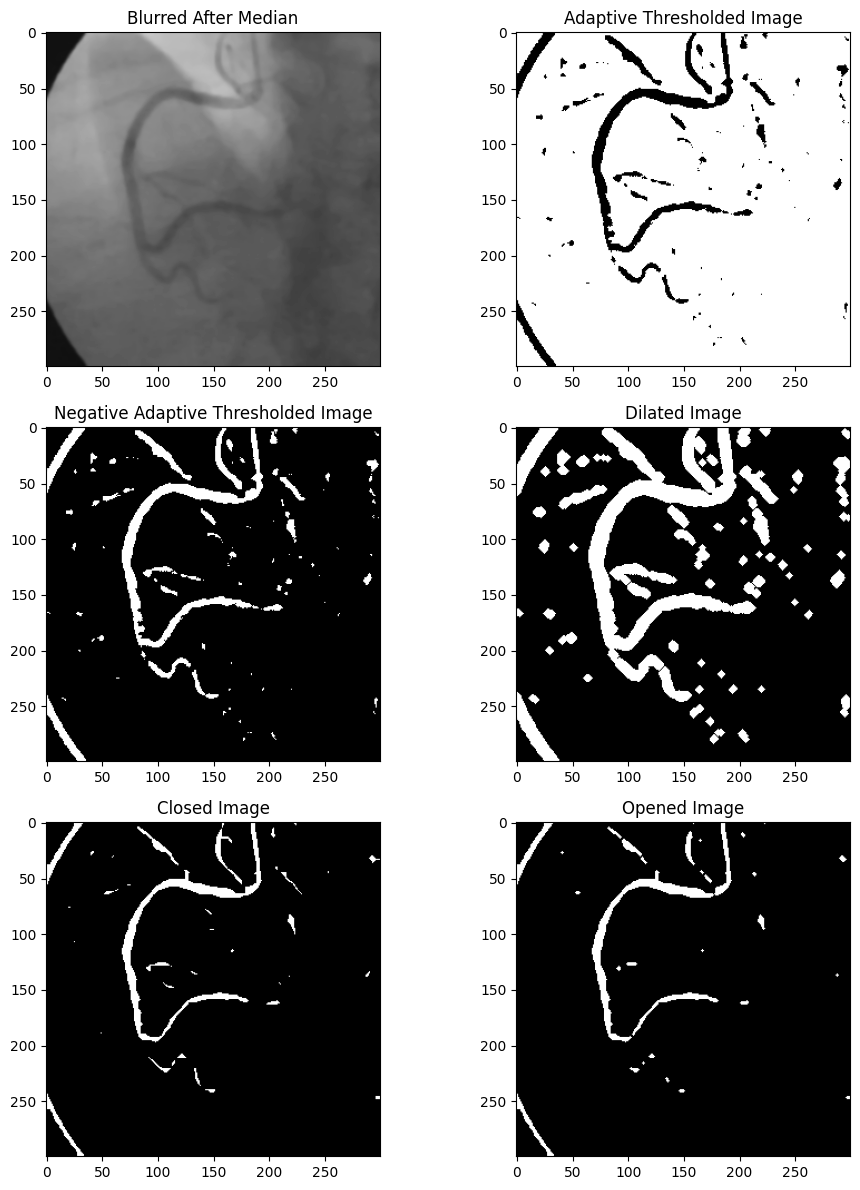

In [289]:
negative_adaptive_tresholed_image = cv.bitwise_not(adaptive_tresholed_image)

dilation_kernel = np.array(cv.getStructuringElement(cv.MORPH_CROSS, (3, 3)), dtype=np.uint8)
dilated_image = cv.dilate(negative_adaptive_tresholed_image, dilation_kernel, iterations=3)
closed_image = cv.erode(dilated_image, np.ones((3, 3), np.uint8), iterations=3)

erosion_kernel = np.array(cv.getStructuringElement(cv.MORPH_CROSS, (3, 3)), dtype=np.uint8)
eroded_image = cv.erode(closed_image, erosion_kernel, iterations=1)
opened_image = cv.dilate(eroded_image, erosion_kernel, iterations=1)



plt.figure(figsize=(10, 12))
plt.subplot(3, 2, 1)
plt.imshow(blureed_after_median, cmap='gray', vmin=0, vmax=255)
plt.title('Blurred After Median')

plt.subplot(3, 2, 2)
plt.imshow(adaptive_tresholed_image, cmap='gray', vmin=0, vmax=255)
plt.title('Adaptive Thresholded Image')
plt.subplot(3, 2, 3)
plt.imshow(negative_adaptive_tresholed_image, cmap='gray', vmin=0, vmax=255)
plt.title('Negative Adaptive Thresholded Image')
plt.subplot(3, 2, 4)
plt.imshow(dilated_image, cmap='gray', vmin=0, vmax=255)
plt.title('Dilated Image')
plt.subplot(3, 2, 5)
plt.imshow(closed_image, cmap='gray', vmin=0, vmax=255)
plt.title('Closed Image')
plt.subplot(3, 2, 6)
plt.imshow(opened_image, cmap='gray', vmin=0, vmax=255)
plt.title('Opened Image')
plt.tight_layout()



(-0.5, 299.5, 299.5, -0.5)

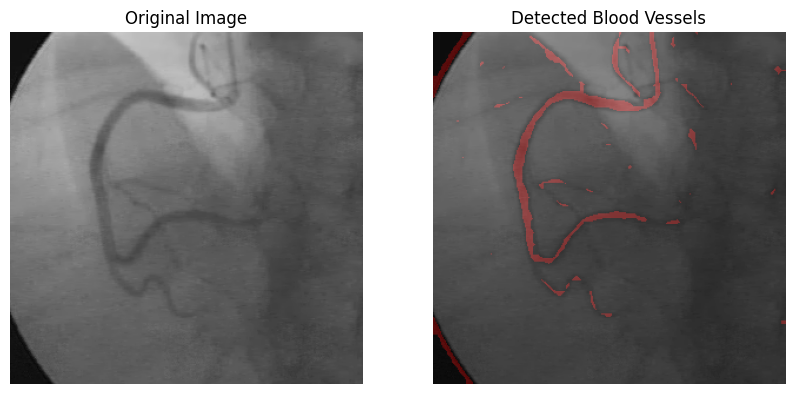

In [290]:
# colored vessels with red color
colored_vessels = np.zeros((closed_image.shape[0], closed_image.shape[1], 3), dtype=np.uint8)
colored_vessels[closed_image == 255] = [255, 0, 0]  # Red color for detected vessels

original_image_colored = cv.cvtColor(image1, cv.COLOR_GRAY2BGR)
colored_vessels = cv.addWeighted(original_image_colored, 0.7, colored_vessels, 0.3, 0)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(original_image_colored)
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(colored_vessels)
plt.title('Detected Blood Vessels')
plt.axis('off')


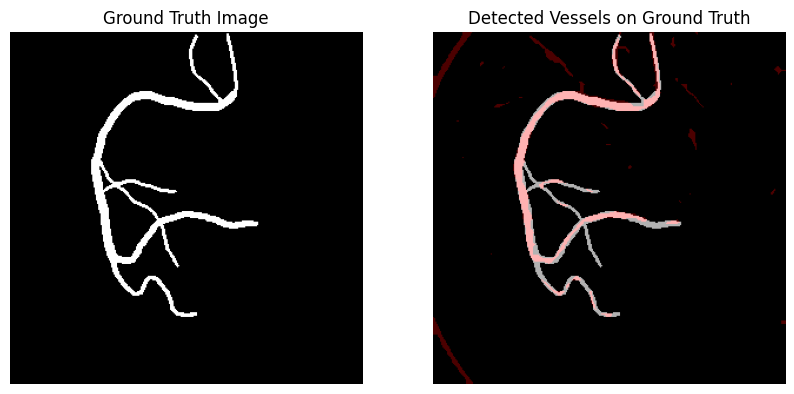

In [291]:
# plot vessels on the ground truth image
ground_truth_image = cv.imread(os.path.join(image_dir, ground_truth_images[0]), cv.IMREAD_GRAYSCALE)
colored_vessels_on_gt = np.zeros((ground_truth_image.shape[0], ground_truth_image.shape[1], 3), dtype=np.uint8)
colored_vessels_on_gt[closed_image == 255] = [255, 0, 0]  # Red color for detected vessels
# ground thruth should be white and vessels should be red
ground_truth_colored = cv.cvtColor(ground_truth_image, cv.COLOR_GRAY2BGR)
ground_truth_colored[ground_truth_image == 255] = [255, 255, 255]  # White color for ground truth vessels
colored_vessels_on_gt = cv.addWeighted(ground_truth_colored, 0.7, colored_vessels_on_gt, 0.3, 0)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(ground_truth_image, cmap='gray')
plt.title('Ground Truth Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(colored_vessels_on_gt)
plt.title('Detected Vessels on Ground Truth')
plt.axis('off')
plt.show()

In [298]:
class BloodVesselSegmentation:
    def __init__(self, image):
        self.image = image
        self.processed_image = None
        self.vessels_image = None

    def preprocess(self):
        # Apply median filter
        median_image = cv.medianBlur(self.image, 5)
        # Apply Gaussian blur
        blurred_image = cv.GaussianBlur(median_image.astype(np.uint8), (3, 3), 0)
        self.processed_image = blurred_image

    def segment_vessels(self):
        if self.processed_image is None:
            raise ValueError("Image must be preprocessed before segmentation.")
        
        # Apply adaptive thresholding
        self.adaptive_thresholded = cv.adaptiveThreshold(self.processed_image.astype(np.uint8), 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 25, 4)
        self.negative_thresholded = cv.bitwise_not(self.adaptive_thresholded)

        # Morphological operations
        self.dilation_kernel = np.array(cv.getStructuringElement(cv.MORPH_CROSS, (3, 3)), dtype=np.uint8)
        self.dilated_image = cv.dilate(self.negative_thresholded, self.dilation_kernel, iterations=3)
        self.closed_image = cv.erode(self.dilated_image, np.ones((3, 3), np.uint8), iterations=3)

        self.erosion_kernel = np.array(cv.getStructuringElement(cv.MORPH_CROSS, (3, 3)), dtype=np.uint8)
        self.eroded_image = cv.erode(self.closed_image, self.erosion_kernel, iterations=1)
        opened_image = cv.dilate(self.eroded_image, self.erosion_kernel, iterations=1)

        self.vessels_image = opened_image
    def visualize_all_steps(self):
        if self.processed_image is None or self.vessels_image is None:
            raise ValueError("Both preprocessing and segmentation must be completed before visualization.")
        
        plt.figure(figsize=(10, 12))
        # plot all the steps
        plt.subplot(4, 2, 1)
        plt.imshow(self.image, cmap='gray', vmin=0, vmax=255)
        plt.title('Original Image')

        plt.subplot(4, 2, 2)
        plt.imshow(self.processed_image, cmap='gray', vmin=0, vmax=255)
        plt.title('Preprocessed Image')

        plt.subplot(4, 2, 3)
        plt.imshow(self.adaptive_thresholded, cmap='gray', vmin=0, vmax=255)
        plt.title('Adaptive Thresholded Image')

        plt.subplot(4, 2, 4)
        plt.imshow(self.negative_thresholded, cmap='gray', vmin=0, vmax=255)
        plt.title('Negative Adaptive Thresholded Image')

        plt.subplot(4, 2, 5)
        plt.imshow(self.dilated_image, cmap='gray', vmin=0, vmax=255)
        plt.title('Dilated Image')

        plt.subplot(4, 2, 6)
        plt.imshow(self.closed_image, cmap='gray', vmin=0, vmax=255)
        plt.title('Closed Image')
        
        plt.subplot(4, 2, 7)
        plt.imshow(self.eroded_image, cmap='gray', vmin=0, vmax=255)
        plt.title('Eroded Image')
        plt.subplot(4, 2, 8)
        plt.imshow(self.vessels_image, cmap='gray', vmin=0, vmax=255)
        plt.title('Opened Image (Final Vessels)')
        plt.tight_layout()
        
    def visualize_vessels_on_ground_truth(self, ground_truth_image):
        if self.vessels_image is None:
            raise ValueError("Segmentation must be completed before visualizing vessels on ground truth.")
        
        colored_vessels_on_gt = np.zeros((ground_truth_image.shape[0], ground_truth_image.shape[1], 3), dtype=np.uint8)
        colored_vessels_on_gt[self.vessels_image == 255] = [255, 0, 0]  # Red color for detected vessels
        
        ground_truth_colored = cv.cvtColor(ground_truth_image, cv.COLOR_GRAY2BGR)
        ground_truth_colored[ground_truth_image == 255] = [255, 255, 255]  # White color for ground truth vessels
        
        combined_image = cv.addWeighted(ground_truth_colored, 0.7, colored_vessels_on_gt, 0.3, 0)
        
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(ground_truth_image, cmap='gray')
        plt.title('Ground Truth Image')
        plt.axis('off')
        
        plt.subplot(1, 2, 2)
        plt.imshow(combined_image)
        plt.title('Detected Vessels on Ground Truth')
        plt.axis('off')
        
        

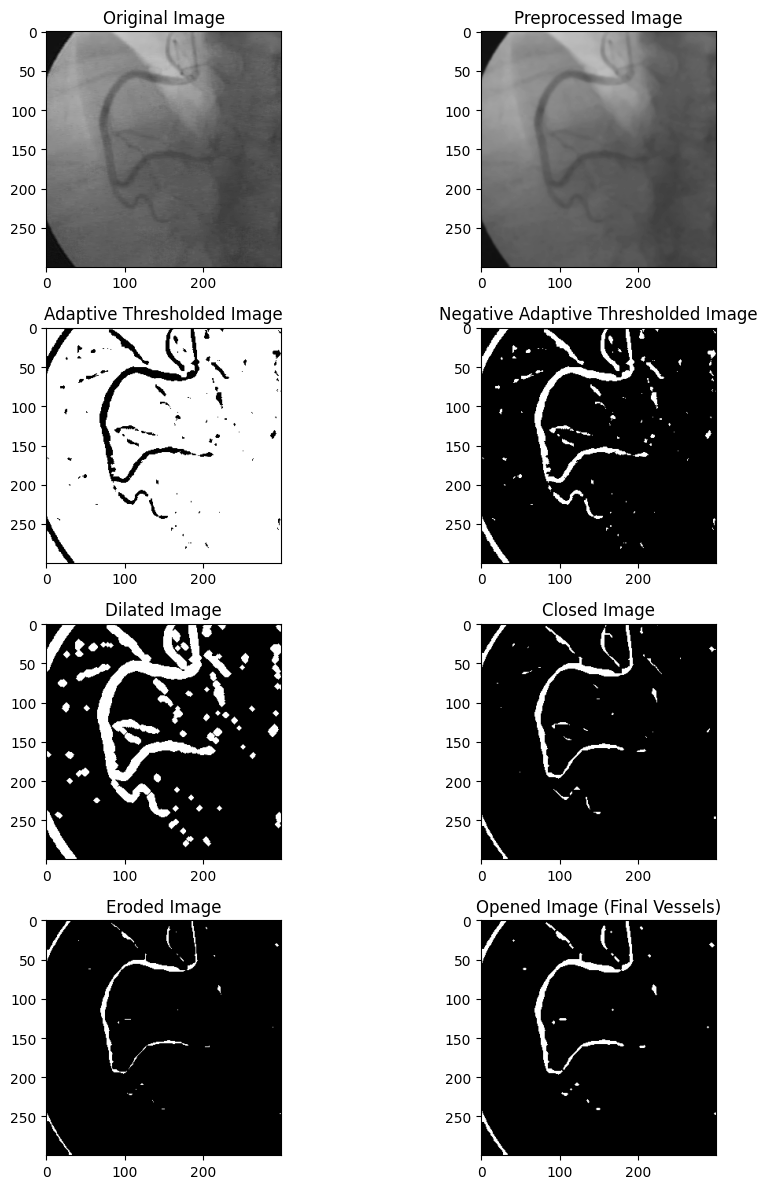

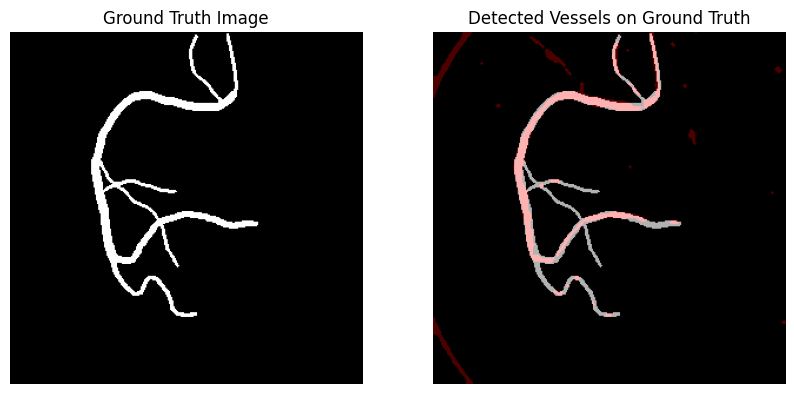

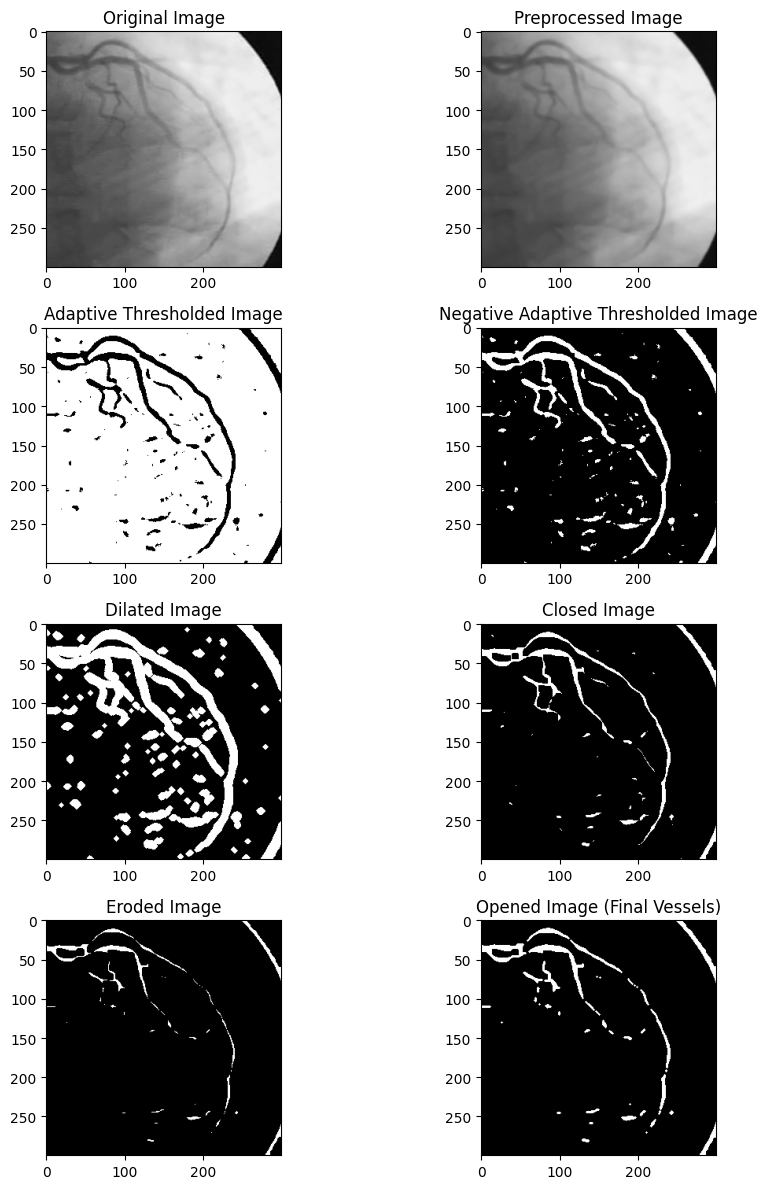

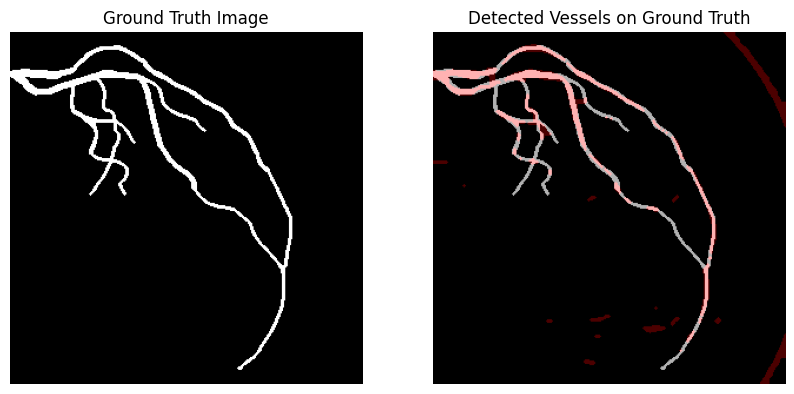

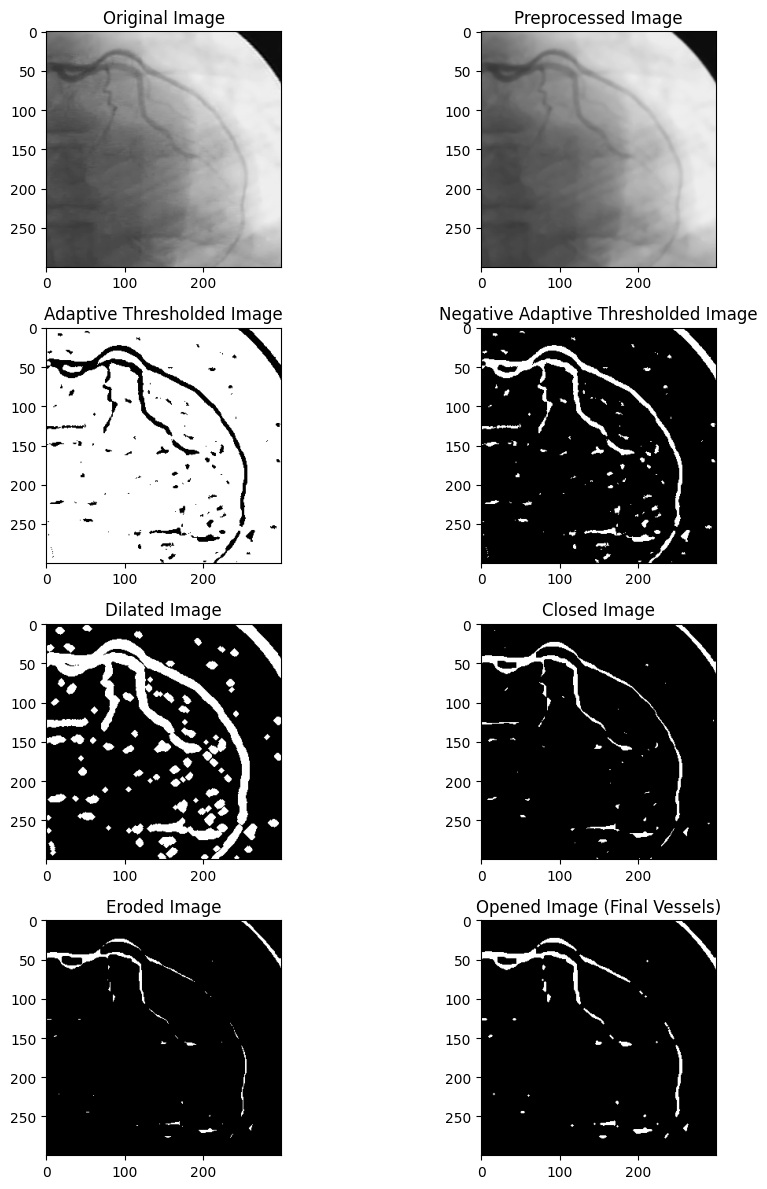

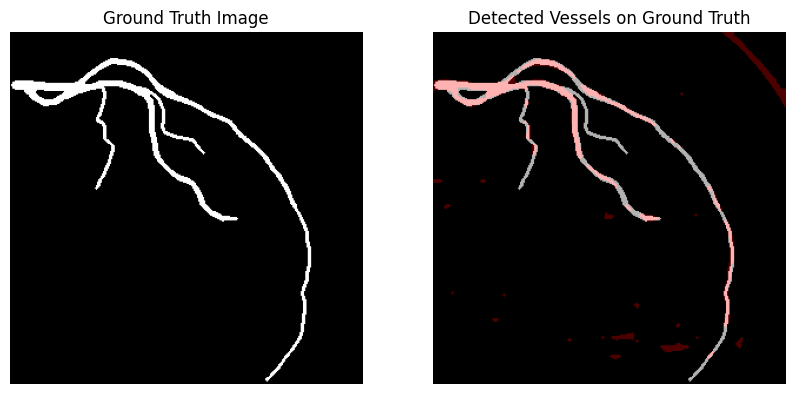

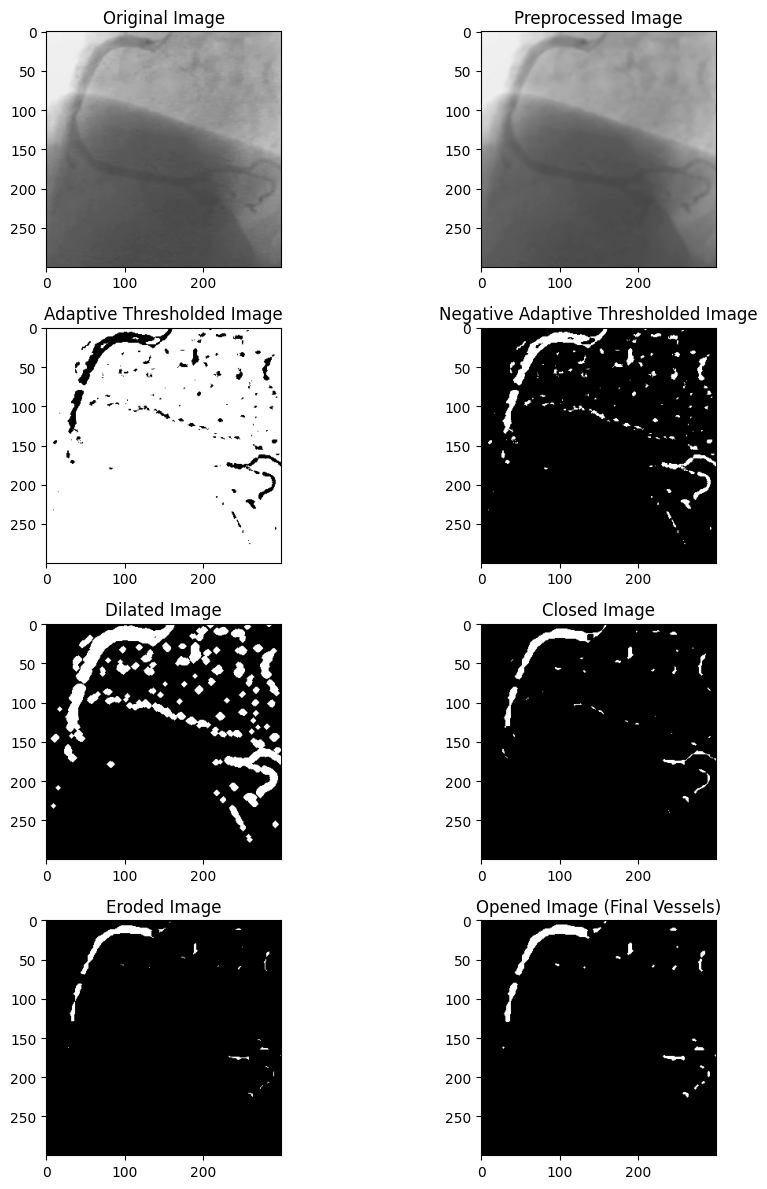

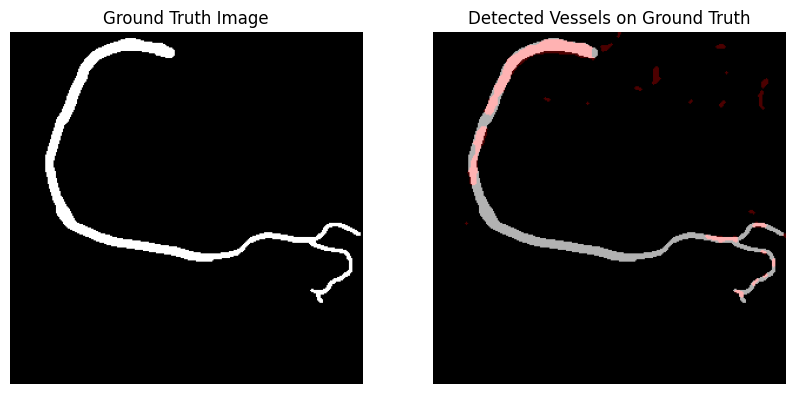

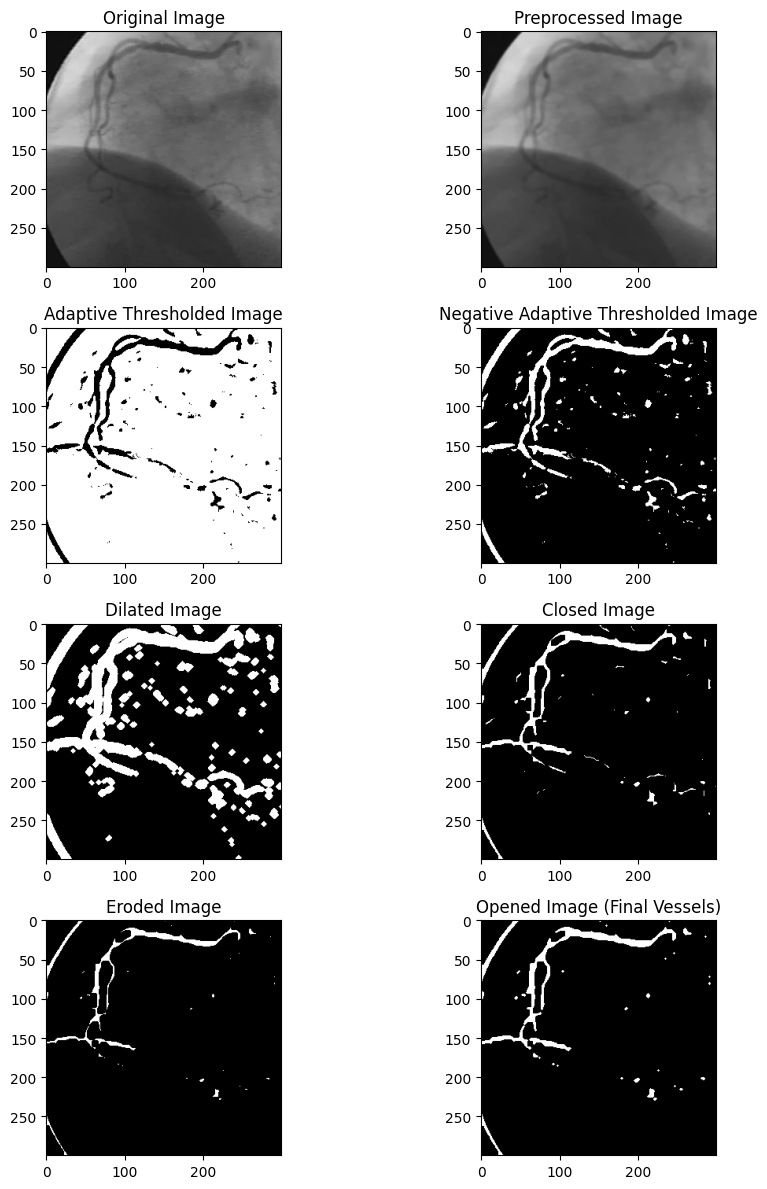

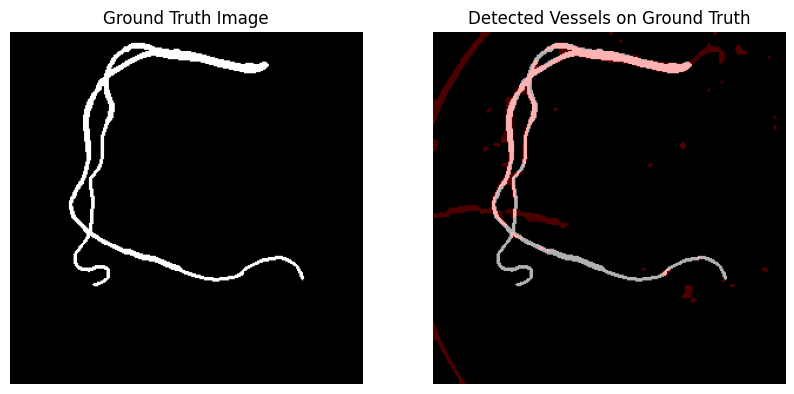

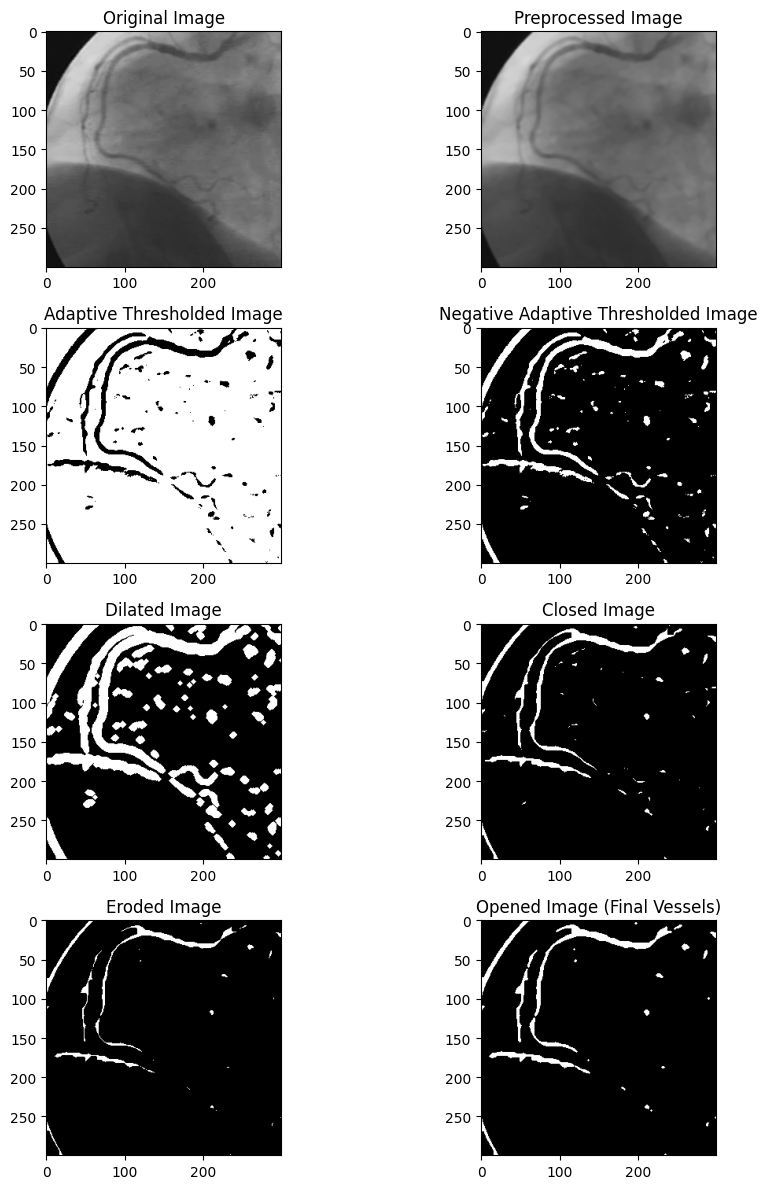

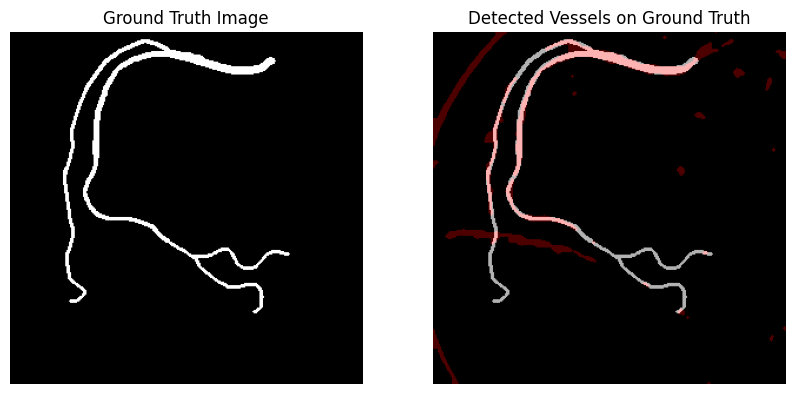

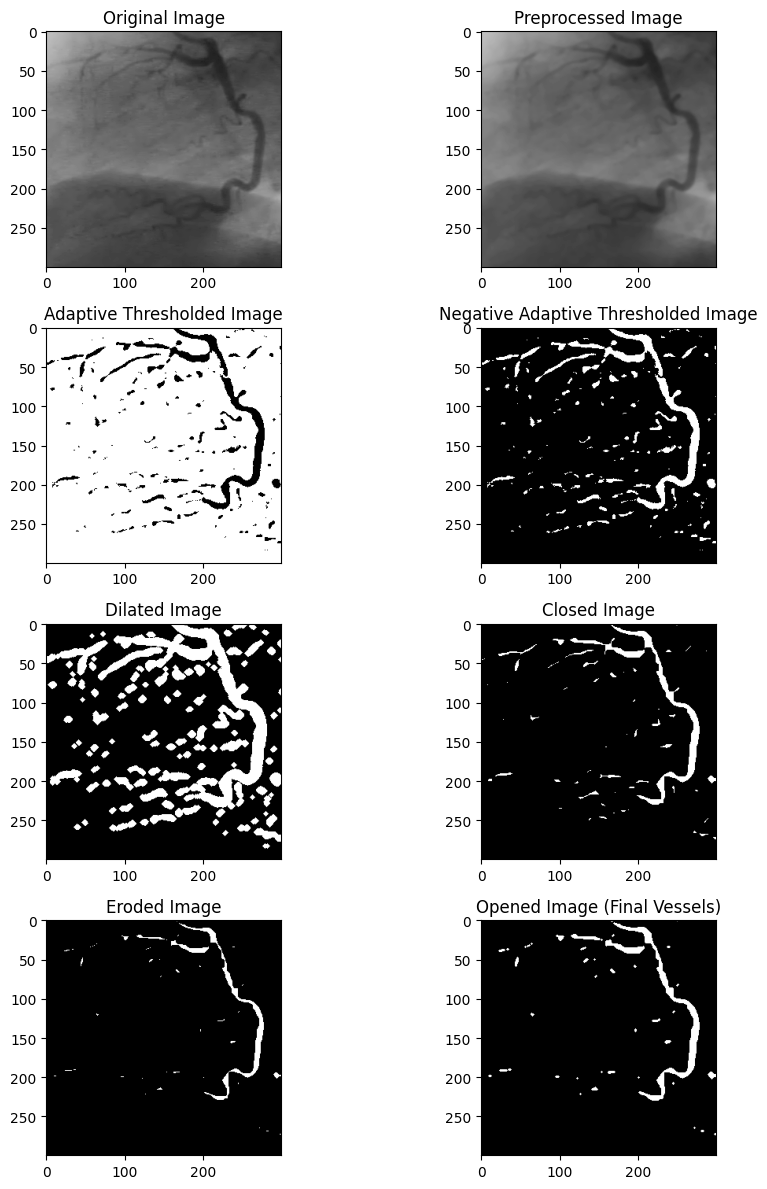

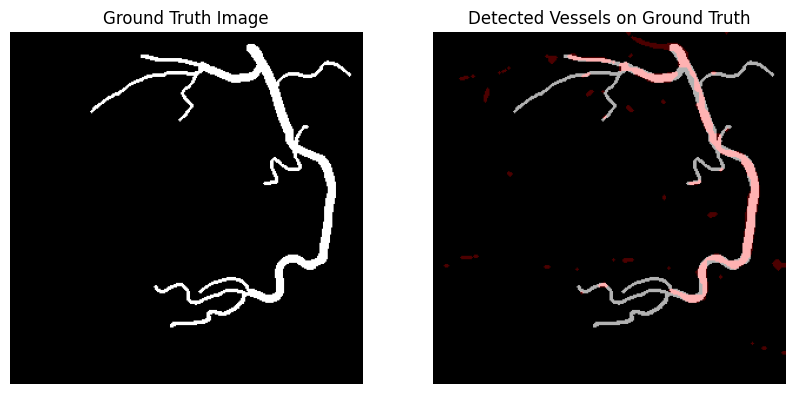

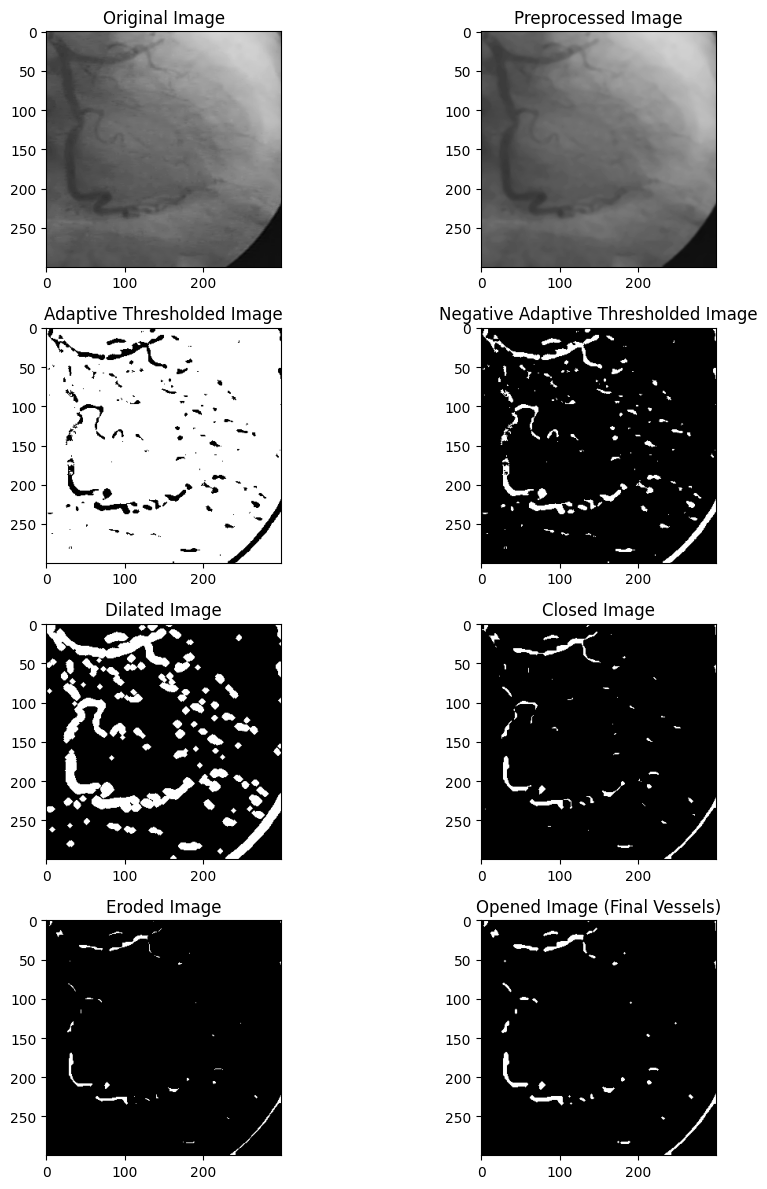

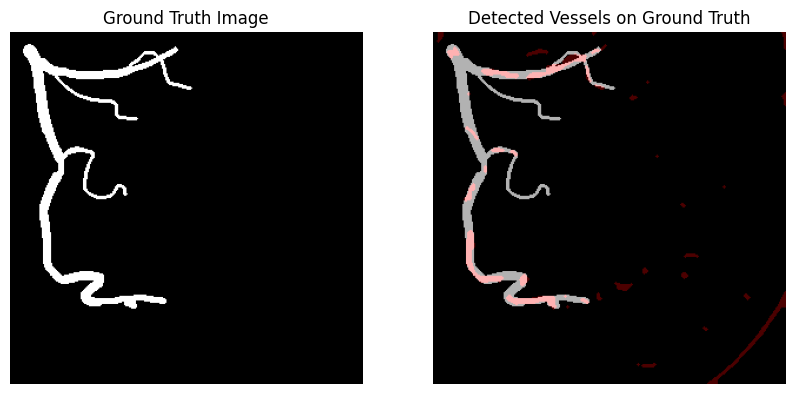

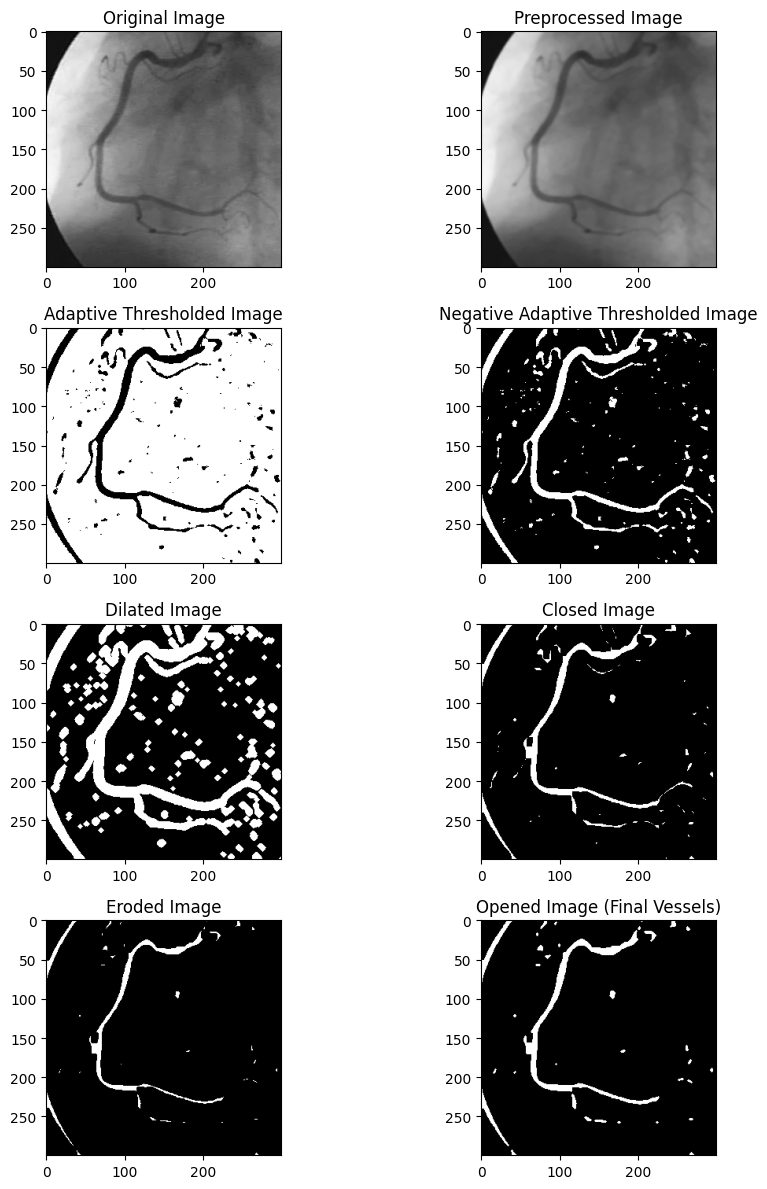

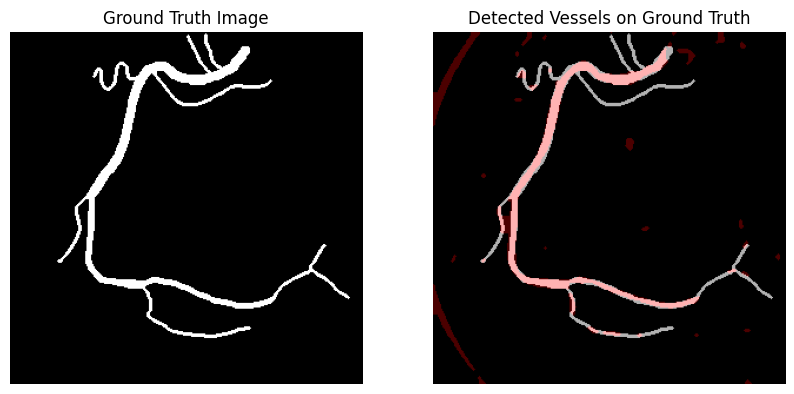

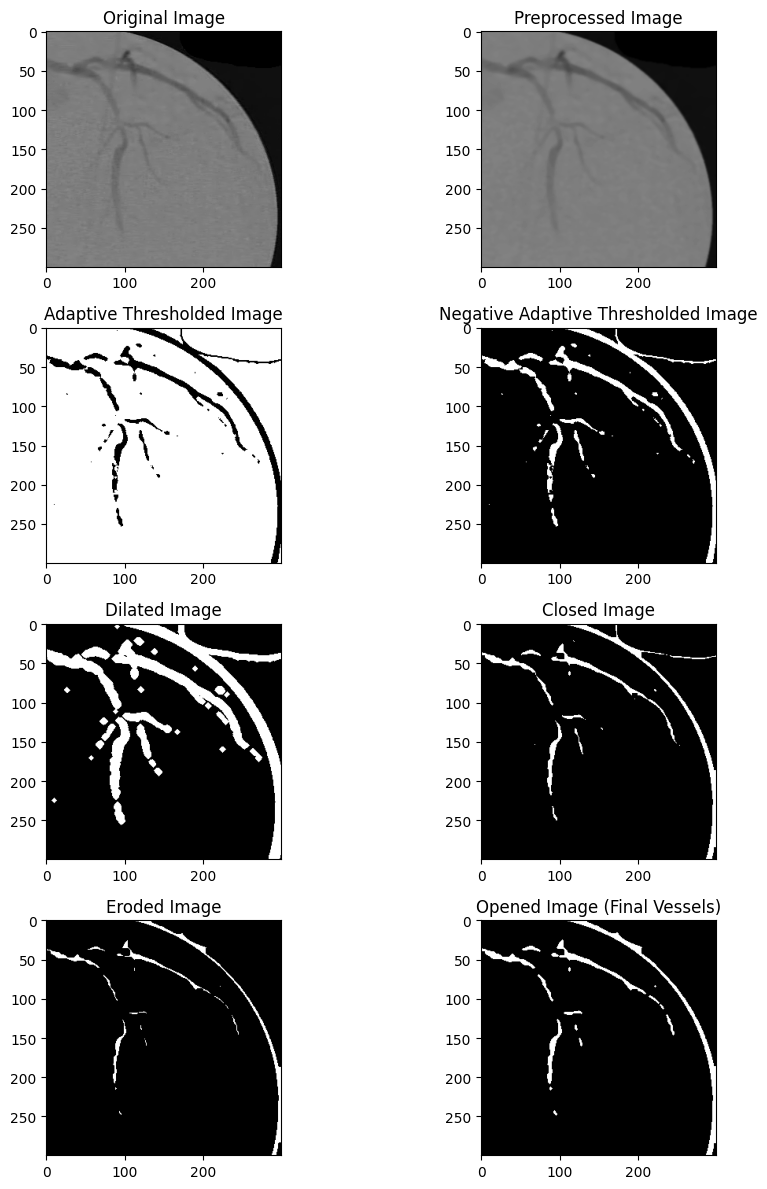

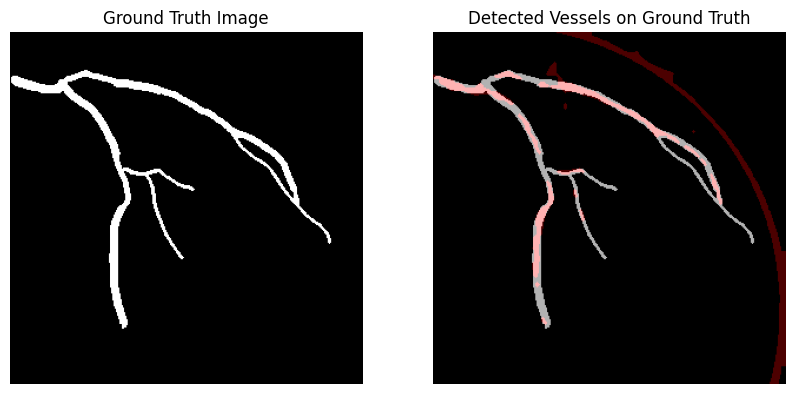

In [299]:
# plot vessels on the ground truth image for the first 10 images
for i in range(10):
    image = cv.imread(os.path.join(image_dir, original_images[i]), cv.IMREAD_GRAYSCALE)
    ground_truth_image = cv.imread(os.path.join(image_dir, ground_truth_images[i]), cv.IMREAD_GRAYSCALE)
    
    segmentation = BloodVesselSegmentation(image)
    segmentation.preprocess()
    segmentation.segment_vessels()
    segmentation.visualize_all_steps()
    segmentation.visualize_vessels_on_ground_truth(ground_truth_image)
    